In [3]:
import sys; sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from src.load.datenbank import abfrage

In [4]:
df = abfrage("""
SELECT z.zaehlstelle_code, s.streckentyp, z.zeitpunkt, z.anzahl, z.qualitaet,
       w.niederschlag_mm, w.temperatur_c, w.wind_kmh,
       f.datum IS NOT NULL AS feiertag
FROM zaehlung z
JOIN zaehlstelle s ON s.zaehlstelle_code = z.zaehlstelle_code
JOIN wetter w ON w.zeitpunkt = z.zeitpunkt + INTERVAL 1 HOUR
LEFT JOIN feiertag f ON f.datum = DATE(z.zeitpunkt)
WHERE z.qualitaet IN ('ok','rekonstruiert')
""")
df.shape, df.anzahl.isna().sum()

((857400, 9), np.int64(0))

In [6]:
df = df.dropna(subset=["niederschlag_mm", "temperatur_c", "wind_kmh"])
df["stunde"] = df.zeitpunkt.dt.hour
df["wochentag"] = df.zeitpunkt.dt.day_of_week   # Mo = 0
df["monat"] = df.zeitpunkt.dt.month
df["regen"] = df.niederschlag_mm >= 0.1
len(df), df.regen.mean()

(851996, np.float64(0.08549453283818234))

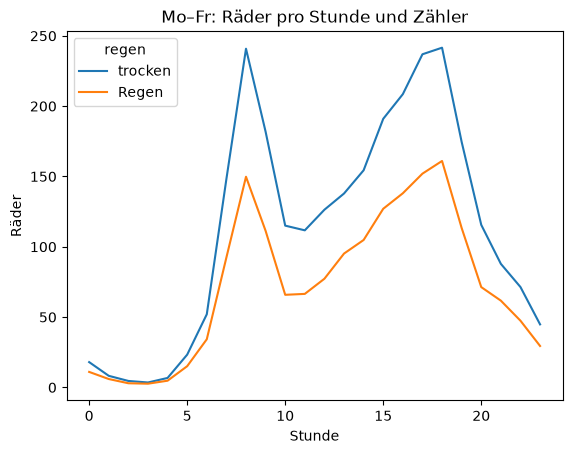

In [7]:
t = df[(df.wochentag < 5) & (df.feiertag == 0)]
t.groupby(["stunde", "regen"]).anzahl.mean().unstack().rename(columns={False: "trocken", True: "Regen"}).plot(title="Mo–Fr: Räder pro Stunde und Zähler", xlabel="Stunde", ylabel="Räder")
plt.show()